# Exploratory Gene Expression Analysis
This notebook explores gene-expression patterns in B cells in samples labelled as smokers and non-smokers.

The workflow includes CSV parsing, group-level descriptive statistics, ranking by absolute differences in mean expression, and heatmap visualisation.

This is an exploratory educational analysis. It does not perform statistical hypothesis testing or establish clinically validated biomarkers.

## Setup and Data Loading

In [24]:
from pathlib import Path
import csv
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files
except ImportError:
    files = None

if files is not None:
    print("Upload GDS3713-small.csv")
    uploaded = files.upload()

    if len(uploaded) != 1:
      raise ValueError("Please upload exactly one CSV file.")

    filename, contents = next(iter(uploaded.items()))
    FILE_PATH = Path(filename)

    #ensure this path contains the bytes selected in this upload
    FILE_PATH.write_bytes(contents)

else:
    FILE_PATH = Path("GDS3713-small.csv")

if not FILE_PATH.is_file():
    raise FileNotFoundError(
        f"Input file not found: {FILE_PATH}."
        "Upload the CSV in Colab or keep it in the local data folder."
    )
print(f"Reading: {FILE_PATH}")

Upload GDS3713-small.csv


Saving GDS3713-small.csv to GDS3713-small (2).csv
Reading: GDS3713-small (2).csv


In [25]:
#main function
def read_patients_data(file_path):

  with open(file_path, encoding="utf-8-sig", newline="") as f:
      reader = csv.reader(f, delimiter=",")

      first_row = next(reader)
      gene_names = first_row[:-1]

      next(reader) #skip the feature-type metadata row
      next(reader) #skip the class metadata row

      patient_id = 1
      definitive_patient_data = {}

      for row in reader:
        if len(row) != len(first_row):
          raise ValueError(
              f"Patient {patient_id}: expected {len(first_row)}"
              f"columns, found{len(row)}"
          )
        stress_status = row[-1].strip()  #smoker or control
        expression_values = row[:-1]
        genes_dict = {}
        for gene_name, expression in zip(gene_names, expression_values): #create tuples of gene name and respective expression
          genes_dict[gene_name] = float(expression) #we create key-value couples in the dictionary, where gene name is the key and expression is the value
        preliminary_patient_data = {
            "stress": stress_status, #put the stress status in the dictionary
            "genes": genes_dict
          }
        definitive_patient_data[f"patient_{patient_id}"] = preliminary_patient_data #create a dynamic key for definitive_patient_data, based on patient_id
        patient_id += 1

  return definitive_patient_data

In [26]:
patient_dictionary = read_patients_data(FILE_PATH)

expected_groups = {"control", "cigarette smoke"}
observed_groups = {sample["stress"] for sample in patient_dictionary.values()}
unexpected_groups = observed_groups - expected_groups

if unexpected_groups:
   raise ValueError(f"Unexpected group labels found: {unexpected_groups}")
if observed_groups != expected_groups:
   raise ValueError("Both control and cigarette smoke groups are required.")

group_counts = Counter(sample["stress"] for sample in patient_dictionary.values())
print(f"Samples loaded {len(patient_dictionary)}")
print(f"Group counts: {dict(group_counts)}")

if patient_dictionary:
   first_sample = next(iter(patient_dictionary.values()))
   print(f"Features in first sample: {len(first_sample['genes'])}")

Samples loaded 79
Group counts: {'control': 40, 'cigarette smoke': 39}
Features in first sample: 3000


## Descriptive Statistics

In [27]:
def genes_statistical_analysis (patient_data): #to calculate the mean, variance, and standard deviation for each gene
  smokers = {}
  non_smokers = {}

  for patient, data in patient_data.items():
      gene_expressions = data["genes"]
      is_smoker = data["stress"] == "cigarette smoke" #if stress, then smoker

      for gene, expression in gene_expressions.items():
          if is_smoker:
            if gene not in smokers:
               smokers[gene] = []
            smokers[gene].append(expression)
          else:
            if gene not in non_smokers:
               non_smokers[gene]=[]
            non_smokers[gene].append(expression)

            '''
            if patient is a smoker, we add their gene expression to the list of values for that gene among all smokers
            if they are a non-smoker, we do the same but using the dictionary for non-smokers
            '''
  #calculate the mean, variance, and standard deviation for smokers
  smoker_data = []
  for gene, expressions in smokers.items():
    mean = np.mean(expressions)
    variance = np.var(expressions)
    standard_deviation = np.std(expressions)
    smoker_data.append({"Gene": gene, "Group":"Smokers", "Mean": mean, "Variance": variance, "Standard Deviation": standard_deviation})

  #now for non-smokers
  non_smoker_data = []
  for gene, expressions in non_smokers.items():
    mean = np.mean(expressions)
    variance = np.var(expressions)
    standard_deviation = np.std(expressions)
    non_smoker_data.append({"Gene": gene, "Group":"Non-Smokers", "Mean": mean, "Variance": variance, "Standard Deviation": standard_deviation})

  dataframe = pd.DataFrame(smoker_data + non_smoker_data)
  return dataframe

df_gene_stats = genes_statistical_analysis(patient_dictionary)

## Differences in Mean Expression

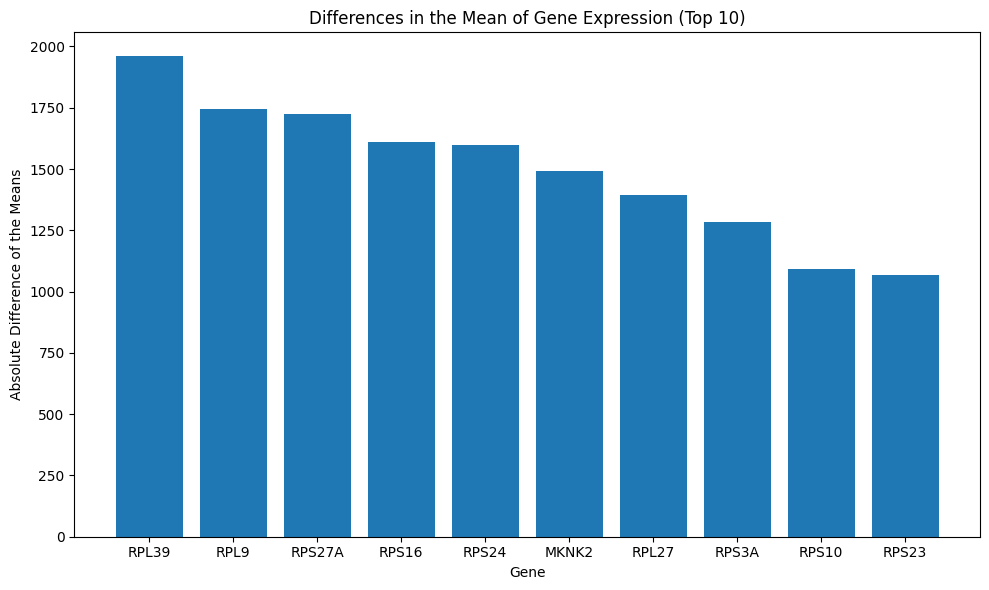

In [28]:
# Plot the largest absolute differences in group mean expression.
def mean_difference_histogram(dataframe, top_n=10): #visualise only 10 genes with biggest differences
    pivot_dataframe = dataframe.pivot(index='Gene', columns='Group', values='Mean') #genes as rows, groups as columns

    pivot_dataframe['Difference'] = abs(pivot_dataframe['Smokers'] - pivot_dataframe['Non-Smokers']) #calculate difference of means between smokers and non-smokers for each gene

    pivot_dataframe = pivot_dataframe.sort_values(by='Difference', ascending=False).head(top_n) #sort, and select the first 10

    plt.figure(figsize=(10, 6))
    plt.bar(pivot_dataframe.index, pivot_dataframe['Difference'])
    plt.xlabel("Gene")
    plt.ylabel("Absolute Difference of the Means")
    plt.title(f"Differences in the Mean of Gene Expression (Top {top_n})")
    plt.tight_layout()
    plt.show()

mean_difference_histogram(df_gene_stats)

## Within-group Variability

In [29]:
def gene_variability_smokers(dataframe, top_n=10): #same process for genes with greatest variance
    smoker_dataframe = dataframe[dataframe['Group'] == 'Smokers'].sort_values(by='Variance', ascending=False).head(top_n)
    return smoker_dataframe['Gene'].tolist()

print("Genes that vary the most among the smokers are:", gene_variability_smokers(df_gene_stats))

Genes that vary the most among the smokers are: ['RPS23', 'RPL9', 'RPL3', 'RPS10', 'RPS3A', 'RPL39', 'TMSB10', 'HLA-DRA', 'RPS24', 'RPS16']


## Log2 Fold-Change Heatmap


 Top 20 upregulated genes in smokers :
ARHGAP22,CHAT,RXRG,DNAH2,OTOF,ZNF557,RDH5,CRIP2,LEPREL2,AGRP,ITGB1BP2,OGDH,CFAP43,MARK2,IQCH,TPH1,INSL6,DHX35,POC1B,SCAMP4

 Top 20 downregulated genes in smokers :
KLF17P1,HIST1H2BJ,HAB1,CPVL,PPCDC,NAG18,FAM66D,CGB7,JMJD7,CD7,SPATA31C2,HK3,GZMH,FABP2,ANKS1B,TRPV6,HBA2,ZNF205,AK026947,LOC100505761


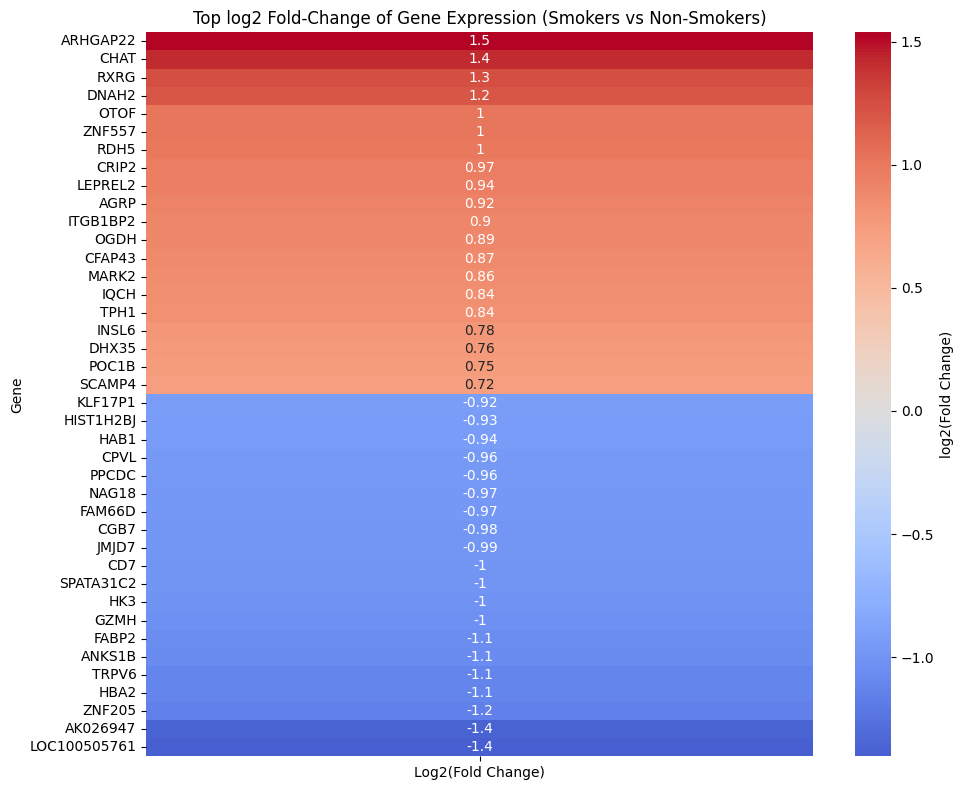

In [30]:
#function to calculate and visualise log2 fold-change of gene expression between smokers and non-smokers
def log2_fold_change_heatmap(patient_data, top_n=20): #visualise 20 genes
  smokers = {}
  non_smokers = {}

  for patient, data in patient_data.items():
     for gene, value in data["genes"].items():
        if data["stress"] == "cigarette smoke":
          smokers.setdefault(gene, []).append(value)
        else:
          non_smokers.setdefault(gene, []).append(value)

  fold_changes = {}
  for gene in smokers:
    if gene in non_smokers and len(non_smokers[gene]) > 0:
      smoker_avg = np.mean(smokers[gene]) #
      non_smoker_avg = np.mean(non_smokers[gene])
      if non_smoker_avg != 0:
        f_change = smoker_avg / non_smoker_avg #how much more (or less) is a gene expressed in smokers?
        fold_changes[gene] = np.log2(f_change)

  #select the top most upregulated and downregulated genes based on the absolute fold change value
  upregulated = sorted([(gene, fc) for gene, fc, in fold_changes.items() if fc > 0], key = lambda x: x[1], reverse = True)[:top_n]
  downregulated = sorted([(gene, fc) for gene, fc, in fold_changes.items() if fc < 0], key = lambda x: x[1])[:top_n]
  downregulated = downregulated[::-1]

  #extract the names of genes
  up_gene_names = [gene for gene, _ in upregulated]
  down_gene_names = [gene for gene, _ in downregulated]
  print("\n Top", top_n, "upregulated genes in smokers :")
  print(",".join(up_gene_names))
  print("\n Top", top_n, "downregulated genes in smokers :")
  print(",".join(down_gene_names))

  #create a matrix for the heatmap
  top_genes = up_gene_names + down_gene_names
  selected_genes = upregulated + downregulated
  genes = [gene for gene, _ in selected_genes]
  values = [[fc] for _, fc in selected_genes]

  #create a Dataframe (rows = genes, columns = log2(foldchange))
  heatmap_df = pd.DataFrame(values, index=genes, columns=["Log2(Fold Change)"])

  plt.figure(figsize=(10, 8))
  sns.heatmap(heatmap_df,
              annot=True,
              cmap="coolwarm", center = 0,
              cbar_kws={"label":"log2(Fold Change)"})
  plt.title("Top log2 Fold-Change of Gene Expression (Smokers vs Non-Smokers)")
  plt.ylabel("Gene")
  plt.tight_layout()
  plt.show()

  return top_genes

top_genes = log2_fold_change_heatmap(patient_dictionary)

## Sample-Level Expression Heatmap

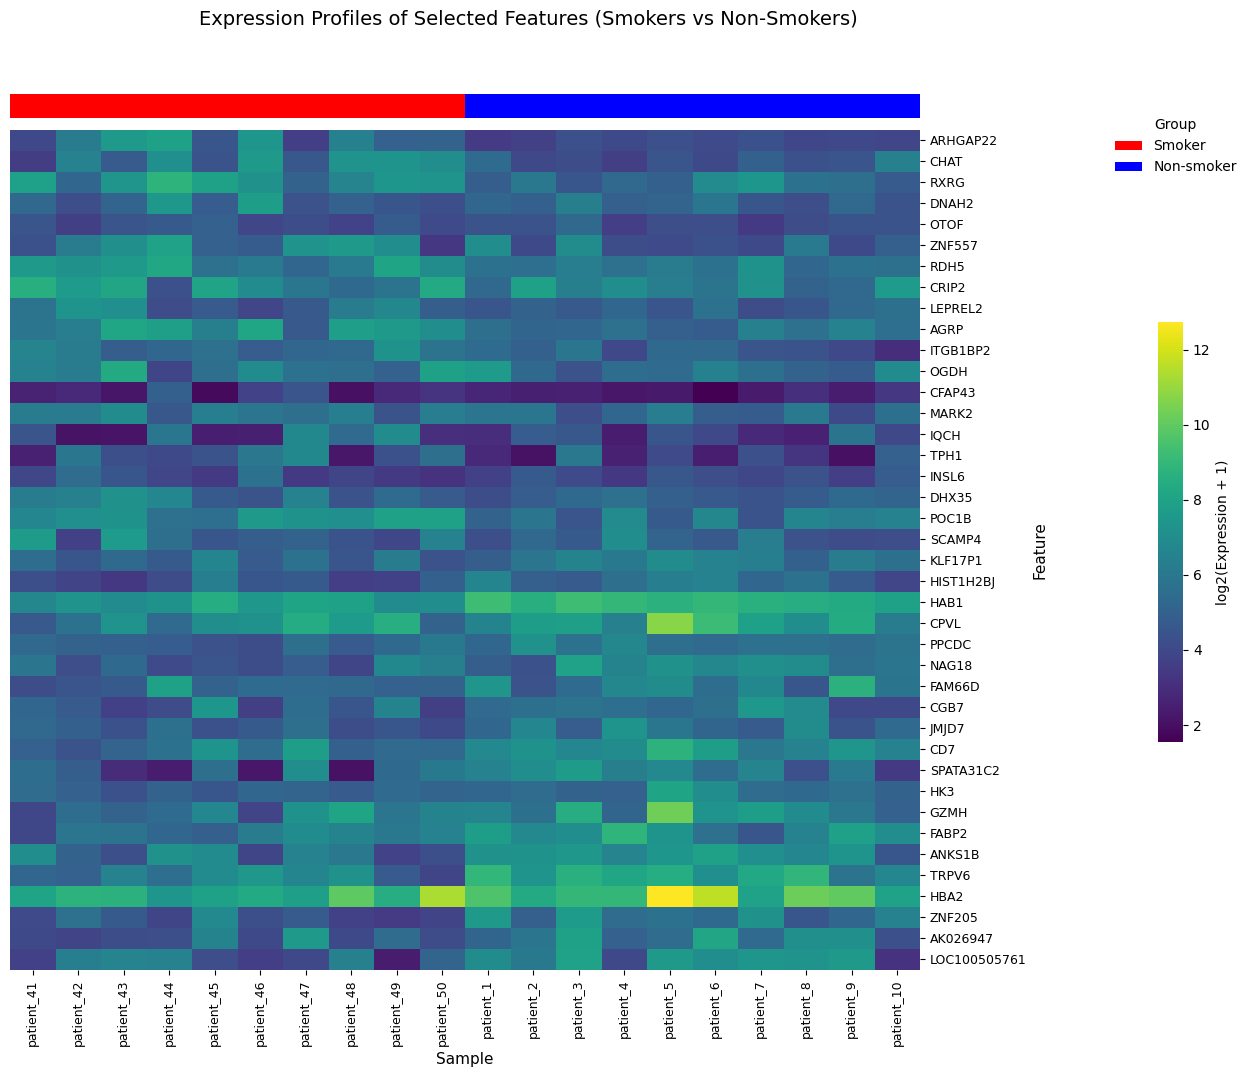

In [31]:
#function to visualise real gene expression
def expression_heatmap(patient_data, genes = None, max_smokers = 10, max_non_smokers = 10):
  smokers = [patient for patient, data in patient_data.items() if data["stress"] == "cigarette smoke"][:max_smokers]
  non_smokers = [patient for patient, data in patient_data.items() if data["stress"] != "cigarette smoke"][:max_non_smokers]
  selected_patients = smokers + non_smokers

  if genes is None:
    all_genes = set()
    for data in patient_data.values():
      all_genes.update(data["genes"].keys())
    genes = list(all_genes)

  #create a matrix (rows are genes, columns are patients)
  expression_matrix = {}
  for patient in selected_patients:
    expr = [patient_data[patient]["genes"].get(gene, np.nan) for gene in genes]
    expression_matrix[patient] = expr

  df = pd.DataFrame(expression_matrix, index = genes)

  #log2 transformation (+1 to avoid log(0))
  df_log2 = np.log2(df + 1)

  from matplotlib.patches import Patch
  group_labels = ['Smoker' if p in smokers else 'Non-smoker' for p in selected_patients]
  col_colors = ['red' if label == 'Smoker' else 'blue' for label in group_labels]
  legend_elements = [Patch(facecolor='red', label='Smoker'), Patch(facecolor='blue', label='Non-smoker')]

  #clustermap with annotations for each group (without clustering)
  g = sns.clustermap(df_log2, cmap="viridis", col_cluster=False, row_cluster=False,
                     col_colors=col_colors, figsize=(14, 12), xticklabels=True,
                     yticklabels=True, cbar_kws={"label":"log2(Expression + 1)"})

  g.ax_row_dendrogram.set_visible(False)
  g.ax_col_dendrogram.set_visible(False)

  g.ax_heatmap.set_position([0.08, 0.16, 0.65, 0.70])
  g.ax_col_colors.set_position([0.08, 0.87, 0.65, 0.02])
  g.cax.set_position([0.90, 0.35, 0.018, 0.35])

  g.fig.suptitle(
        "Expression Profiles of Selected Features "
        "(Smokers vs Non-Smokers)",
        x=0.45,
        y=0.96,
        fontsize=14
    )

  g.ax_heatmap.set_xlabel("Sample", fontsize=11)
  g.ax_heatmap.set_ylabel("Feature", fontsize=11)

  g.ax_heatmap.tick_params(axis="x", labelrotation=90, labelsize=9)
  g.ax_heatmap.tick_params(axis="y", labelrotation=0, labelsize=9)

  g.ax_col_colors.set_xticks([])
  g.ax_col_colors.set_yticks([])
  g.ax_col_colors.set_xlabel("")
  g.ax_col_colors.set_ylabel("")

  g.fig.legend(handles=legend_elements, title="Group", loc="upper left",
                      bbox_to_anchor=(0.86, 0.88), frameon=False)

  plt.show()

expression_heatmap(patient_dictionary, genes = top_genes)

## Interpretation and Limitations
 - The analysis is descriptive and exploratory.
 - Features are ranked by observed mean difference or log2 fold changes, not by statistical significance.
 - No hypothesis testing, multiple-testing correction, or adjustment for confounding variables is performed.
 - Variance and standard deviation use NumPy's default population definitions ('ddof=0')
 - Fold changes are calculated as the ratio of group means on the input expression scale. Their interpretation requires checking the preprocessing and scale of the source data.
 - The sample-level heatmap displays log2(expression + 1) values and uses a limited number of samples per group.
 - Row and column clustering are disabled.
 - The CSV parser assumes numeric expression values and a correctly formatted input file.